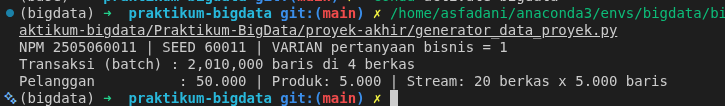

## Tahap 1 – Penyimpanan Terdistribusi dan Ingesti (HDFS)
- Buat struktur direktori di HDFS, misalnya /tidarmart/raw/transaksi, /tidarmart/raw/pelanggan, /tidarmart/raw/produk, /tidarmart/stream_input, /tidarmart/curated, /tidarmart/models.
- Unggah seluruh data ke HDFS. Tampilkan bukti ukuran, jumlah blok, dan faktor replikasi (hdfs dfs -du -h, hdfs fsck).
- Baca seluruh data dari HDFS (hdfs://localhost:9000/...) bukan dari path lokal pada tahap-tahap berikutnya.
- Jelaskan: mengapa data mentah dan data bersih dipisah direktori, dan apa arti replikasi = 1 pada VM pseudo-distributed dibanding klaster nyata

In [1]:
# Membuat struktur direktori
!hdfs dfs -mkdir -p user/asfadani/tidarmart/raw/transaksi
!hdfs dfs -mkdir -p user/asfadani/tidarmart/raw/pelanggan
!hdfs dfs -mkdir -p user/asfadani/tidarmart/raw/produk
!hdfs dfs -mkdir -p user/asfadani/tidarmart/stream_input
!hdfs dfs -mkdir -p user/asfadani/tidarmart/curated
!hdfs dfs -mkdir -p user/asfadani/tidarmart/models

# cek direktori
!hdfs dfs -ls user/asfadani/tidarmart

Found 4 items
drwxr-xr-x   - asfadani supergroup          0 2026-11-23 23:11 user/asfadani/tidarmart/curated
drwxr-xr-x   - asfadani supergroup          0 2026-11-23 23:11 user/asfadani/tidarmart/models
drwxr-xr-x   - asfadani supergroup          0 2026-11-23 23:11 user/asfadani/tidarmart/raw
drwxr-xr-x   - asfadani supergroup          0 2026-11-23 23:11 user/asfadani/tidarmart/stream_input


In [2]:
# Unggah file lokal ke hdfs
!hdfs dfs -put -f /home/asfadani/praktikum-bigdata/data_proyek/transaksi user/asfadani/tidarmart/raw
!hdfs dfs -put -f /home/asfadani/praktikum-bigdata/data_proyek/stream_input user/asfadani/tidarmart
!hdfs dfs -put -f /home/asfadani/praktikum-bigdata/data_proyek/pelanggan.json user/asfadani/tidarmart/raw/pelanggan
!hdfs dfs -put -f /home/asfadani/praktikum-bigdata/data_proyek/produk.json user/asfadani/tidarmart/raw/produk

# Menampilkan bukti
!hdfs dfs -du -h user/asfadani/tidarmart
!hdfs fsck /user/asfadani/user/asfadani/tidarmart -files -blocks -locations

0        0        user/asfadani/tidarmart/curated
0        0        user/asfadani/tidarmart/models
193.8 M  193.8 M  user/asfadani/tidarmart/raw
9.4 M    9.4 M    user/asfadani/tidarmart/stream_input
Connecting to namenode via http://localhost:9870/fsck?ugi=asfadani&files=1&blocks=1&locations=1&path=%2Fuser%2Fasfadani%2Fuser%2Fasfadani%2Ftidarmart
FSCK started by asfadani (auth:SIMPLE) from /127.0.0.1 for path /user/asfadani/user/asfadani/tidarmart at Mon Nov 23 23:34:27 WIB 2026

/user/asfadani/user/asfadani/tidarmart <dir>
/user/asfadani/user/asfadani/tidarmart/curated <dir>
/user/asfadani/user/asfadani/tidarmart/models <dir>
/user/asfadani/user/asfadani/tidarmart/raw <dir>
/user/asfadani/user/asfadani/tidarmart/raw/pelanggan <dir>
/user/asfadani/user/asfadani/tidarmart/raw/pelanggan/pelanggan.json 6308351 bytes, replicated: replication=1, 1 block(s):  OK
0. BP-1524836457-127.0.1.1-1788400594758:blk_1073741921_1097 len=6308351 Live_repl=1  [DatanodeInfoWithStorage[127.0.0.1:9866,DS-f

>Data mentah dan data bersih harus dipisah karena untuk kerapian dan kemudahan dalam mengaksesnya. Data mentah beersifat immutable (tidak boleh dirubah) karena berfungsi sebagai sumber kebenaran utama. Dimana jika saat proses pengolahan terdapat kesalahan, masih ada titik 0 datanya yang bisa diolah kembali. Selain itu, jika file jadi dengan file mentah disatukan kita akan bingung jika suatu saat ingin membutuhkan filenya untuk sebuah projek. Selain itu juga menyimpan file dengan kondisi berbeda juga menjadi salah satu syarat clean architecture di dunia pemrograman. Pembagian penyimpanan data ini juga memudahkan dalam pengerjaan kolaborasi, sehingga orang lain yang akan mengakses datanya tidak kebingungan. Dalam pelacakan perubahan dari datanya juga menjadi mudah jika datanya disimpan ke folder yang berbeda. Selain itu juga membuat proses lebih efisien pada pipeline project, untuk mengatur data diambil dari mana dan akan disimpan di mana nantinya.

>Maksud dari replikasi 1 adalah jumlah replikasi (copy/redudan) data yang disimpan. Dalam indstri nyata bidang bigdata data wajib direplikasi ke beberapa tempat (umumnya 3 DataNode) untuk mengamankan data jika ada salah satu yang bermasalah. Data tidak akan langsung error karena sudah ada backupnya. Dalam VM psudeo distributed ini hanya meniru cara kerja di dunia nyata industri bigdata dengan menerapkan di project ini. Dan karena hanya jalan di 1 mesin VM, maka replikasi yang dipakai hanya 1 (menyesuaikan tempat).


___

## Tahap 2 – Profiling Kualitas Data (Veracity)
- Hitung jumlah baris, jumlah order_id unik, persentase nilai kosong per kolom, jumlah harga negatif, distribusi qty (temukan outlier dengan kuantil, jenis nya bebas), dan variasi penulisan kota
- Sajikan hasil profiling dalam satu tabel ringkasan “sebelum pembersihan”.
- Untuk profil pelanggan dan produk: tunjukkan bahwa atribut produk bervariasi menurut kategori (berapa persen produk memiliki setiap atribut) dan bagaimana field tags diperlakukan

In [3]:
# Koneksi ke HDFS
from pyarrow import fs

hdfs = fs.HadoopFileSystem(host='localhost', port=9000)
print(hdfs.get_file_info(fs.FileSelector('/')))

2026-11-26 12:38:52,460 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


[<FileInfo for '/home': type=FileType.Directory>, <FileInfo for '/user': type=FileType.Directory>]


In [2]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder
        .appName('TidarMart')
        .master('local[2]')
        .config('spark.driver.memory', '1536m')
        .config('spark.sql.shuffle.partitions', '4')
        .config('spark.sql.adaptive.enabled', 'true')
        .getOrCreate()
        )

print("spark session siap. Versi spark:", spark.version)

26/11/26 12:38:40 WARN Utils: Your hostname, asfadani resolves to a loopback address: 127.0.1.1; using 172.17.0.1 instead (on interface docker0)
26/11/26 12:38:40 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/26 12:38:41 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/26 12:38:43 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


spark session siap. Versi spark: 3.5.9


In [3]:
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DoubleType, ArrayType, DateType

# Baca data transaksi
df_transaksi = spark.read.csv('/user/asfadani/user/asfadani/tidarmart/raw/transaksi/transaksi_part*.csv', header=True, inferSchema=True)

# Baca data json
# struktur data yang saya lihat dari file {"pelanggan_id": 1, "nama": "Pelanggan-1", "kota": "Solo", "tanggal_daftar": "2025-07-01", "membership": "Silver"}
schema_pelanggan = StructType([
    StructField("pelanggan_id", IntegerType(), True),
    StructField("nama", StringType(), True),
    StructField("kota", StringType(), True),
    StructField("tanggal_daftar", DateType(), True),
    StructField("membership", StringType(), True)
])

df_pelanggan = spark.read.schema(schema_pelanggan).json('/user/asfadani/user/asfadani/tidarmart/raw/pelanggan/pelanggan.json')

'''
Struktur di data produk
{"produk_id": 1, "nama_produk": "Elektronik-1", "kategori": "Elektronik", "harga_dasar": 40000, "berat_kg": 2.0, "garansi_bulan": 6, "voltase": 110}
{"produk_id": 2, "nama_produk": "Kesehatan-2", "kategori": "Kesehatan", "harga_dasar": 60000, "berat_kg": 1.68}
{"produk_id": 3, "nama_produk": "Otomotif-3", "kategori": "Otomotif", "harga_dasar": 350000, "berat_kg": 11.04}
{"produk_id": 4, "nama_produk": "Buku-4", "kategori": "Buku", "harga_dasar": 25000, "berat_kg": 4.74, "penerbit": "Gramedia", "tags": ["lokal"]}
{"produk_id": 5, "nama_produk": "Makanan-5", "kategori": "Makanan", "harga_dasar": 120000, "berat_kg": 6.91, "kadaluarsa_hari": 30}
{"produk_id": 21, "nama_produk": "Fashion-21", "kategori": "Fashion", "harga_dasar": 120000, "berat_kg": 5.11, "ukuran": "S", "bahan": "poliester"}
'''
schema_produk = StructType([
    StructField("produk_id", IntegerType(), True),
    StructField("nama_produk", StringType(), True),
    StructField("kategori", StringType(), True),
    StructField("harga_dasar", IntegerType(), True),
    StructField("berat_kg", DoubleType(), True),
    StructField("garansi_bulan", IntegerType(), True),
    StructField("voltase", IntegerType(), True),
    StructField("penerbit", StringType(), True),
    StructField("tags", ArrayType(StringType()), True),
    StructField("bahan", StringType(), True),
    StructField("ukuran", StringType(), True)
])

df_produk = spark.read.schema(schema_produk).json('/user/asfadani/user/asfadani/tidarmart/raw/produk/produk.json')


In [4]:
# melakukan proffiling pada data transaksi
import pandas as pd
from pyspark.sql.functions import col, sum, when, round

# hitung jumlah baris
baris_transaksi = df_transaksi.count()

# id unik => id yang tidak terduplikasi
id_unik = df_transaksi.groupBy("order_id").count().count()

# persentase data kosong tiap kolom
null_kolom = df_transaksi.select([
    round((sum(when(col(c).isNull(), 1).otherwise(0)) / baris_transaksi) * 100, 2 ).alias(c)
    for c in df_transaksi.columns
]).first() # first => method untuk store data hasil aggregasi ke variable
mull_rapi = ", ".join([f"{k}: {v}%" for k, v in null_kolom.asDict().items() if v > 0])

# jumlah harga negatif
harga_negatif = df_transaksi.select(col('harga_satuan')).filter(col('harga_satuan') <= 0)

# outlier
summary = df_transaksi.select('qty').summary('mean', 'stddev', 'min', '25%', '50%', '75%', 'max').collect()
summary_rapi = ", ".join([f"{r[0]}: {r[1]}" for r in summary])

# variasi penulisan kota
variasi_kota = df_transaksi.groupBy('kota').count().orderBy(col('count').desc()).collect()
variasi_rapi = ", ".join([f"{r['kota']}: {r['count']}" for r in variasi_kota])

profilling = {
    'jumlah_baris': baris_transaksi,
    'jumlah_id_unik': id_unik,
    'persentase_missing_value': mull_rapi,
    'jumlah_harga_negatif': harga_negatif.count(),
    'distribusi_qty': summary_rapi,
    'variasi_kota': variasi_rapi
}

df_profilling = pd.DataFrame(profilling, index=['Sebelum Pembersihan'])

pd.set_option('display.max_colwidth', None) # agar tidak terpotong kolomnya
display(df_profilling.T)

,Sebelum Pembersihan
jumlah_baris,2010000
jumlah_id_unik,2000000
persentase_missing_value,"qty: 0.3%, harga_satuan: 0.3%"
jumlah_harga_negatif,1964
distribusi_qty,"mean: 4.513881202476973, stddev: 22.684339546523898, min: 1.0, 25%: 2.0, 50%: 4.0, 75%: 6.0, max: 999.0"
variasi_kota,"Semarang: 239734, Kebumen: 239133, Magelang: 238674, Temanggung: 238660, Wonosobo: 238656, Solo: 238435, Yogyakarta: 238376, Purworejo: 238081, YOGYAKARTA: 6362, SEMARANG: 6322, yogyakarta: 6313, kebumen: 6307, semarang: 6291, purworejo: 6291, SOLO: 6281, WONOSOBO: 6269, TEMANGGUNG: 6267, magelang: 6262, MAGELANG: 6257, temanggung: 6248, solo: 6213, PURWOREJO: 6206, wonosobo: 6199, KEBUMEN: 6163"


In [5]:
print("Jumlah baris data pelanggan:", df_pelanggan.count())
print("Jumlah baris data produk:", df_produk.count())

Jumlah baris data pelanggan: 50000
Jumlah baris data produk: 5000


In [6]:
from pyspark.sql.functions import count
df_produk.groupBy('kategori').agg(
    *[round(count(c) / count('produk_id') *100, 2).alias(c)
    for c in df_produk.columns if c != 'kategori']
).show()

+------------+---------+-----------+-----------+--------+-------------+-------+--------+-----+-----+------+
|    kategori|produk_id|nama_produk|harga_dasar|berat_kg|garansi_bulan|voltase|penerbit| tags|bahan|ukuran|
+------------+---------+-----------+-----------+--------+-------------+-------+--------+-----+-----+------+
|     Makanan|    100.0|      100.0|      100.0|   100.0|          0.0|    0.0|     0.0|29.95|  0.0|   0.0|
|    Olahraga|    100.0|      100.0|      100.0|   100.0|          0.0|    0.0|     0.0|26.66|  0.0|   0.0|
|  Elektronik|    100.0|      100.0|      100.0|   100.0|        100.0|  100.0|     0.0| 30.2|  0.0|   0.0|
|    Otomotif|    100.0|      100.0|      100.0|   100.0|          0.0|    0.0|     0.0|25.04|  0.0|   0.0|
|Rumah Tangga|    100.0|      100.0|      100.0|   100.0|          0.0|    0.0|     0.0|28.92|  0.0|   0.0|
|   Kesehatan|    100.0|      100.0|      100.0|   100.0|          0.0|    0.0|     0.0| 29.1|  0.0|   0.0|
|        Buku|    100.0|    

In [7]:
print("Id unik data pelanggan", df_pelanggan.groupBy('pelanggan_id').count().count())
df_pelanggan.select([
    sum(
        when(col(c).isNull(), 1).otherwise(0)).alias(c)
        for c in df_pelanggan.columns
    ]).show()

Id unik data pelanggan 50000
+------------+----+----+--------------+----------+
|pelanggan_id|nama|kota|tanggal_daftar|membership|
+------------+----+----+--------------+----------+
|           0|   0|   0|             0|         0|
+------------+----+----+--------------+----------+



>Field tags akan akan dibaca sebagai arraytype, dan dokumen yang tidak memiliki tag akan tetap dipertahankan karena tidakmeimiliki tag tidak menandakan data rusak. Saat pembersihan bisa diisi dengan array kosong

___

## Tahap 3 – ETL dan Penyimpanan Kolumnar (Parquet)
- Bersihkan transaksi sesuai temuan Tahap 2: deduplikasi, penanganan nilai kosong, harga negatif, outlier qty, normalisasi nama kota. Setiap aturan harus disertai alasan (dibuang, diisi, atau dikoreksi, dan mengapa).
- Tambahkan kolom turunan: total_nilai (qty × harga_satuan × (1 − diskon/100)), bulan, hari_dalam_minggu, flag_batal.
- Simpan hasil ke HDFS /tidarmart/curated dalam format Parquet dengan partitionBy yang Anda pilih dan justifikasikan (misalnya kota atau bulan)
- Bandingkan CSV dan Parquet: ukuran di HDFS dan waktu eksekusi satu query agregasi yang sama. Sajikan dalam tabel.
- Tampilkan laporan “sesudah pembersihan” berdampingan dengan laporan sebelumnya.

In [10]:
# Data cleaning

# menghilangkan duplikasi
print("Jumlah baris (masih ada duplikat):", df_transaksi.count())
transaksi_clean = df_transaksi.dropDuplicates()
print("Jumlah baris (setelah cleaning 1):", transaksi_clean.count())

Jumlah baris (masih ada duplikat): 2010000


[Stage 63:>                                                         (0 + 2) / 2]

Jumlah baris (setelah cleaning 1): 2000000


In [11]:
# nenangani data kosong
transaksi_clean = transaksi_clean.dropna()
print("Jumlah baris (setelah cleaning 2):", transaksi_clean.count())

[Stage 69:>                                                         (0 + 2) / 2]

Jumlah baris (setelah cleaning 2): 1987999


In [14]:
# menangani harga negatif, outlier
transaksi_clean = transaksi_clean.filter((col('qty') != 999) & (col('harga_satuan') > 0)) 
print("Jumlah baris (setelah cleaning 3):", transaksi_clean.count())

[Stage 75:>                                                         (0 + 2) / 2]

Jumlah baris (setelah cleaning 3): 1985019


In [16]:
# koreksi variasi kota
map_kota = {
    "semarang": "Semarang",
    "SEMARANG": "Semarang",
    "kebumen": "Kebumen",
    "KEBUMEN": "Kebumen",
    "magelang": "Magelang",
    "MAGELANG": "Magelang",
    "temanggung": "Temanggung",
    "TEMANGGUNG": "Temanggung",
    "wonosobo": "Wonosobo",
    "WONOSOBO": "Wonosobo",
    "solo": "Solo",
    "SOLO": "Solo",
    "yogyakarta": "Yogyakarta",
    "YOGYAKARTA": "Yogyakarta",
    "purworejo": "Purworejo",
    "PURWOREJO": "Purworejo"
}

transaksi_clean = transaksi_clean.replace(to_replace=map_kota, subset=["kota"])
transaksi_clean.groupBy("kota").count().show()

[Stage 81:>                                                         (0 + 2) / 2]

+----------+------+
|      kota| count|
+----------+------+
|  Semarang|249154|
| Purworejo|247434|
|  Wonosobo|248075|
|Yogyakarta|247901|
|      Solo|247896|
|Temanggung|248104|
|   Kebumen|248439|
|  Magelang|248016|
+----------+------+



>Semua proses cleaning saya hilangkan (drop), karena jika di imputasi dengan nilai lain atau nilai statistika dari keseluruhan data (mean/median/modus/std deviasi) akan n menyebabkan data leakage di saat tahap modeling nantinya. Kecuali jika memang ingin diimputasi dengan nilai statistik di tahap ini harus dipertahankan dulu, baru nanti ditahap modeling (setelah di split) baru diimputasi dengan nilai statistika dari data training nya di kedua data .

In [17]:
transaksi_clean.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- tanggal: timestamp (nullable = true)
 |-- pelanggan_id: integer (nullable = true)
 |-- produk_id: integer (nullable = true)
 |-- qty: double (nullable = true)
 |-- harga_satuan: double (nullable = true)
 |-- diskon_persen: integer (nullable = true)
 |-- metode_pembayaran: string (nullable = true)
 |-- kota: string (nullable = true)
 |-- berat_kg: double (nullable = true)
 |-- jarak_km: double (nullable = true)
 |-- lama_kirim_hari: integer (nullable = true)
 |-- status_pesanan: string (nullable = true)



In [18]:
transaksi_clean.select('status_pesanan').show(5)

[Stage 87:>                                                         (0 + 1) / 1]

+--------------+
|status_pesanan|
+--------------+
|       Selesai|
|       Selesai|
|       Selesai|
|       Selesai|
|       Selesai|
+--------------+
only showing top 5 rows



In [20]:
# menambah kolom turunan
from pyspark.sql.functions import month, dayofweek

# kolom total_nilai
transaksi_clean = transaksi_clean.withColumn("total_nilai", col("qty") * col("harga_satuan") * (1 - col("diskon_persen")/100))

# kolom bulan
transaksi_clean = transaksi_clean.withColumn("bulan", month(col('tanggal')))

# kolom hari dalam minggu
transaksi_clean = transaksi_clean.withColumn('hari_dalam_minggu', dayofweek(col('tanggal')))

# kolom flag batal
transaksi_clean = transaksi_clean.withColumn('flag_batal', when(col('status_pesanan') == "Selesai", 0).otherwise(1))

transaksi_clean.select('total_nilai', 'bulan', 'hari_dalam_minggu', 'flag_batal').show(5)

[Stage 90:>                                                         (0 + 1) / 1]

+-----------+-----+-----------------+----------+
|total_nilai|bulan|hari_dalam_minggu|flag_batal|
+-----------+-----+-----------------+----------+
|   425000.0|    3|                5|         0|
|   120000.0|    5|                1|         0|
|    85500.0|    6|                6|         0|
|    40000.0|    3|                6|         0|
|   224000.0|    1|                3|         0|
+-----------+-----+-----------------+----------+
only showing top 5 rows



In [21]:
# simpan dengan format parquet ke hdfs (partitionBy => kota)

transaksi_clean.write.mode("overwrite").partitionBy('kota').parquet(
    "hdfs://localhost:9000/user/asfadani/user/asfadani/tidarmart/curated"
)

print("Data clean sudah tersimpan di HDFS")
!hdfs dfs -ls /user/asfadani/user/asfadani/tidarmart/curated

Data clean sudah tersimpan di HDFS
Found 9 items
-rw-r--r--   1 asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadani/tidarmart/curated/_SUCCESS
drwxr-xr-x   - asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadani/tidarmart/curated/kota=Kebumen
drwxr-xr-x   - asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadani/tidarmart/curated/kota=Magelang
drwxr-xr-x   - asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadani/tidarmart/curated/kota=Purworejo
drwxr-xr-x   - asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadani/tidarmart/curated/kota=Semarang
drwxr-xr-x   - asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadani/tidarmart/curated/kota=Solo
drwxr-xr-x   - asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadani/tidarmart/curated/kota=Temanggung
drwxr-xr-x   - asfadani supergroup          0 2026-11-25 20:54 /user/asfadani/user/asfadan

In [23]:
# lilhat ukuran parquet vs csv
!hdfs dfs -du -h user/asfadani/tidarmart

53.8 M   53.8 M   user/asfadani/tidarmart/curated
0        0        user/asfadani/tidarmart/models
193.8 M  193.8 M  user/asfadani/tidarmart/raw
9.4 M    9.4 M    user/asfadani/tidarmart/stream_input


In [35]:
# membandingkan kecepatan kueri
import time
from pyspark.sql.functions import sum as spark_sum
import builtins

mulai = time.perf_counter()

parquet = (
    spark.read.parquet("hdfs://localhost:9000/user/asfadani/user/asfadani/tidarmart/curated")
    .groupBy("kota")
    .agg(spark_sum("total_nilai"))
    .collect()
)

durasi_pq = builtins.round(time.perf_counter() - mulai, 3)

In [36]:
mulai = time.perf_counter()

parquet = (
    spark.read.csv('/user/asfadani/user/asfadani/tidarmart/raw/transaksi/transaksi_part*.csv', header=True)
    .groupBy("kota")
    .agg(spark_sum("harga_satuan"))
    .collect()
)

durasi_csv = builtins.round(time.perf_counter() - mulai, 3)

In [37]:
perbandingan = {
    "Parquet": durasi_pq,
    "CSV": durasi_csv
}

df_perbandingan = pd.DataFrame(perbandingan, index=["Durasi Kueri"])
display(df_perbandingan)

,Parquet,CSV
Durasi Kueri,0.677,4.204


In [39]:
# melakukan proffiling pada data bersih

# hitung jumlah baris
baris_transaksi_clean = transaksi_clean.count()

# id unik => id yang tidak terduplikasi
id_unik_clean = transaksi_clean.groupBy("order_id").count().count()

# persentase data kosong tiap kolom
null_kolom_clean = transaksi_clean.select([
    round((sum(when(col(c).isNull(), 1).otherwise(0)) / baris_transaksi_clean) * 100, 2 ).alias(c)
    for c in transaksi_clean.columns
]).first() # first => method untuk store data hasil aggregasi ke variable
mull_rapi_clean = ", ".join([f"{k}: {v}%" for k, v in null_kolom_clean.asDict().items() if v > 0])

# jumlah harga negatif
harga_negatif_clean = transaksi_clean.select(col('harga_satuan')).filter(col('harga_satuan') <= 0)

# outlier
summary_clean = transaksi_clean.select('qty').summary('mean', 'stddev', 'min', '25%', '50%', '75%', 'max').collect()
summary_rapi_clean = ", ".join([f"{r[0]}: {r[1]}" for r in summary_clean])

# variasi penulisan kota
variasi_kota_clean = transaksi_clean.groupBy('kota').count().orderBy(col('count').desc()).collect()
variasi_rapi_clean = ", ".join([f"{r['kota']}: {r['count']}" for r in variasi_kota_clean])

profilling_clean = {
    'jumlah_baris': baris_transaksi_clean,
    'jumlah_id_unik': id_unik_clean,
    'persentase_missing_value': mull_rapi_clean,
    'jumlah_harga_negatif': harga_negatif_clean.count(),
    'distribusi_qty': summary_rapi_clean,
    'variasi_kota': variasi_rapi_clean
}

df_profilling_clean = pd.DataFrame(profilling_clean, index=['Setelah Pembersihan'])

df_perbandingan = pd.concat([df_profilling, df_profilling_clean])

pd.set_option('display.max_colwidth', None) # agar tidak terpotong kolomnya
display(df_perbandingan.T)

,Sebelum Pembersihan,Setelah Pembersihan
jumlah_baris,2010000,1985019
jumlah_id_unik,2000000,1985019
persentase_missing_value,"qty: 0.3%, harga_satuan: 0.3%",
jumlah_harga_negatif,1964,0
distribusi_qty,"mean: 4.513881202476973, stddev: 22.684339546523898, min: 1.0, 25%: 2.0, 50%: 4.0, 75%: 6.0, max: 999.0","mean: 4.0003279565586025, stddev: 1.9994236988316987, min: 1.0, 25%: 2.0, 50%: 4.0, 75%: 6.0, max: 7.0"
variasi_kota,"Semarang: 239734, Kebumen: 239133, Magelang: 238674, Temanggung: 238660, Wonosobo: 238656, Solo: 238435, Yogyakarta: 238376, Purworejo: 238081, YOGYAKARTA: 6362, SEMARANG: 6322, yogyakarta: 6313, kebumen: 6307, semarang: 6291, purworejo: 6291, SOLO: 6281, WONOSOBO: 6269, TEMANGGUNG: 6267, magelang: 6262, MAGELANG: 6257, temanggung: 6248, solo: 6213, PURWOREJO: 6206, wonosobo: 6199, KEBUMEN: 6163","Semarang: 249154, Kebumen: 248439, Temanggung: 248104, Wonosobo: 248075, Magelang: 248016, Yogyakarta: 247901, Solo: 247896, Purworejo: 247434"


___

## Tahap 4 – Analitik Batch (DataFrame, Join, Window, Spark SQL)
Gunakan data Parquet bersih. Wajib mengerjakan lima analisis inti (A–E) dan tiga Pertanyaan Bisnis Khusus sesuai angka VARIAN Anda

### Analisis Inti (Semua Mahasiswa)

| Kode | Pertanyaan / Tugas Analisis |
| :--- | :--- |
| **A** | Gabungkan transaksi dengan produk dan pelanggan (*join*). Tampilkan omzet per kategori per kota dan jelaskan strategi *join* yang dipakai (apakah perlu *broadcast*, mengapa). |
| **B** | Tren omzet bulanan dan pertumbuhan dibanding bulan sebelumnya (*window function* `lag`). |
| **C** | Peringkat 5 produk terlaris di setiap kota berdasarkan omzet (*window function* `rank` / `dense_rank` dengan partisi). |
| **D** | Omzet kumulatif (*running total*) per kategori sepanjang waktu serta rata-rata bergerak 7 hari (*window* dengan rentang baris). |
| **E** | Satu analisis yang sama dengan salah satu analisis A–D, ditulis ulang menggunakan Spark SQL (`createOrReplaceTempView`) dan buktikan hasilnya identik. Bandingkan rencana eksekusi dengan `explain()`. |

---

### Pertanyaan Bisnis Khusus — Varian 1
**NPM berakhir 1, 4, 7 | Fokus Nilai Pelanggan**

| Kode | Pertanyaan / Tugas Analisis |
| :--- | :--- |
| **F** | Hitung RFM (*recency*, *frequency*, *monetary*) per pelanggan. Berapa persen pelanggan menyumbang 80% omzet (prinsip Pareto)? |
| **G** | Bandingkan perilaku belanja antar *membership* (Silver, Gold, Platinum): rata-rata nilai pesanan, frekuensi, tingkat pembatalan. |
| **H** | Identifikasi pelanggan berisiko pergi: pelanggan yang pernah aktif tetapi tidak bertransaksi pada 30 hari terakhir data, dan jelaskan profilnya. |


In [14]:
# membaca data
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DoubleType, ArrayType, DateType
from pyspark import StorageLevel

schema_pelanggan = StructType([
    StructField("pelanggan_id", IntegerType(), True),
    StructField("nama", StringType(), True),
    StructField("kota", StringType(), True),
    StructField("tanggal_daftar", DateType(), True),
    StructField("membership", StringType(), True)
])

schema_produk = StructType([
    StructField("produk_id", IntegerType(), True),
    StructField("nama_produk", StringType(), True),
    StructField("kategori", StringType(), True),
    StructField("harga_dasar", IntegerType(), True),
    StructField("berat_kg", DoubleType(), True),
    StructField("garansi_bulan", IntegerType(), True),
    StructField("voltase", IntegerType(), True),
    StructField("penerbit", StringType(), True),
    StructField("tags", ArrayType(StringType()), True),
    StructField("bahan", StringType(), True),
    StructField("ukuran", StringType(), True)
])

df_transaksi = spark.read.parquet("hdfs://localhost:9000/user/asfadani/user/asfadani/tidarmart/curated")
df_pelanggan = spark.read.schema(schema_pelanggan).json('/user/asfadani/user/asfadani/tidarmart/raw/pelanggan/pelanggan.json')
df_produk = spark.read.schema(schema_produk).json('/user/asfadani/user/asfadani/tidarmart/raw/produk/produk.json')
df_transaksi.printSchema()
df_pelanggan.printSchema()
df_produk.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- tanggal: timestamp (nullable = true)
 |-- pelanggan_id: integer (nullable = true)
 |-- produk_id: integer (nullable = true)
 |-- qty: double (nullable = true)
 |-- harga_satuan: double (nullable = true)
 |-- diskon_persen: integer (nullable = true)
 |-- metode_pembayaran: string (nullable = true)
 |-- berat_kg: double (nullable = true)
 |-- jarak_km: double (nullable = true)
 |-- lama_kirim_hari: integer (nullable = true)
 |-- status_pesanan: string (nullable = true)
 |-- total_nilai: double (nullable = true)
 |-- bulan: integer (nullable = true)
 |-- hari_dalam_minggu: integer (nullable = true)
 |-- flag_batal: integer (nullable = true)
 |-- kota: string (nullable = true)

root
 |-- pelanggan_id: integer (nullable = true)
 |-- nama: string (nullable = true)
 |-- kota: string (nullable = true)
 |-- tanggal_daftar: date (nullable = true)
 |-- membership: string (nullable = true)

root
 |-- produk_id: integer (nullable = true)
 |-- nama_p

In [19]:
# menggabungkan 3 data
from pyspark.sql.functions import broadcast, sum as spark_sum, col

df_gabungan = (df_transaksi
    .join(broadcast(df_pelanggan.drop("kota")), on="pelanggan_id", how="left")
    .join(broadcast(df_produk), on="produk_id", how="left").persist(StorageLevel.MEMORY_AND_DISK))

df_gabungan.groupBy("kategori", "kota").agg(
    spark_sum(col('qty') * col('harga_satuan')).alias("omzet")
).orderBy("kota").show()

26/11/26 13:36:20 WARN CacheManager: Asked to cache already cached data.
[Stage 18:>                                                         (0 + 2) / 2]

+------------+---------+------------+
|    kategori|     kota|       omzet|
+------------+---------+------------+
|     Makanan|  Kebumen|3.9271215E10|
|  Elektronik|  Kebumen| 3.606947E10|
|    Olahraga|  Kebumen|4.3099445E10|
|    Otomotif|  Kebumen| 3.647117E10|
|        Buku|  Kebumen|3.4626385E10|
|     Fashion|  Kebumen|3.3424715E10|
|   Kesehatan|  Kebumen| 3.936728E10|
|Rumah Tangga|  Kebumen| 3.649569E10|
|        Buku| Magelang|3.3994285E10|
|    Otomotif| Magelang|3.6624555E10|
|  Elektronik| Magelang|3.5312415E10|
|    Olahraga| Magelang|4.3057715E10|
|     Fashion| Magelang|3.3737445E10|
|Rumah Tangga| Magelang| 3.730564E10|
|     Makanan| Magelang| 3.875921E10|
|   Kesehatan| Magelang| 3.988452E10|
|   Kesehatan|Purworejo|3.9785985E10|
|     Fashion|Purworejo|  3.37342E10|
|        Buku|Purworejo| 3.470818E10|
|  Elektronik|Purworejo|  3.53446E10|
+------------+---------+------------+
only showing top 20 rows



>Join dengan left join agar semua data kanan dicocokan dengan data kiri (data kiri sebagai data fakta, tidak boleh ada yang hilang). Proses join mem broadcast (menyalin data kecil ke memori untuk menghindari shuffleing) data kecil (produk dan pelanggan) untuk meningkatkan effisiensi penggabungan. Setelah itu hasil join di simpan (persist) karena masih digunakan secara berulang, agar kueri lebih cepat (sudah ada yang disimpan).

In [25]:
# soal b
from pyspark.sql.window import Window
from pyspark.sql.functions import round as spark_round, lag

df_bulan = df_gabungan.groupBy("bulan").agg(
    spark_sum(col('qty') * col('harga_satuan')).alias("omzet")
)

window_spec = Window.orderBy("bulan")
df_tren_bulanan = (df_bulan.withColumn("omzet_bulan_sebelumnya", lag("omzet", 1).over(window_spec))
                  .withColumn("selisih_omzet", col('omzet') - col('omzet_bulan_sebelumnya'))
                  .withColumn("pertumbuhan_omzet", spark_round( ((col('omzet')-col('omzet_bulan_sebelumnya')) / col('omzet_bulan_sebelumnya')) * 100, 2 ))
                  ).orderBy('bulan')

df_tren_bulanan.show(truncate=False)

26/11/26 14:12:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/26 14:12:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/26 14:12:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/26 14:12:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/26 14:12:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/26 14:12:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/26 1

+-----+-------------+----------------------+-------------+-----------------+
|bulan|omzet        |omzet_bulan_sebelumnya|selisih_omzet|pertumbuhan_omzet|
+-----+-------------+----------------------+-------------+-----------------+
|1    |4.0772258E11 |NULL                  |NULL         |NULL             |
|2    |3.6731341E11 |4.0772258E11          |-4.040917E10 |-9.91            |
|3    |4.0914138E11 |3.6731341E11          |4.182797E10  |11.39            |
|4    |3.950411E11  |4.0914138E11          |-1.410028E10 |-3.45            |
|5    |4.07199655E11|3.950411E11           |1.2158555E10 |3.08             |
|6    |3.93947935E11|4.07199655E11         |-1.325172E10 |-3.25            |
+-----+-------------+----------------------+-------------+-----------------+



In [33]:
# soal c
from pyspark.sql.functions import dense_rank

df_kota_produk = df_gabungan.groupBy("kota", "nama_produk").agg(
    spark_sum(col('qty') * col('harga_satuan')).alias("omzet")
)

spec = Window.partitionBy("kota").orderBy(col('omzet').desc())

df_omzet_kota = df_kota_produk.withColumn("produk_laris_perkota_omzet", dense_rank().over(spec))

df_omzet_kota.filter(col("produk_laris_perkota_omzet") <= 5).orderBy("kota", "produk_laris_perkota_omzet").show(truncate=False)

[Stage 69:>                                                         (0 + 2) / 2]

+---------+-----------------+-------+--------------------------+
|kota     |nama_produk      |omzet  |produk_laris_perkota_omzet|
+---------+-----------------+-------+--------------------------+
|Kebumen  |Kesehatan-1893   |4.83E8 |1                         |
|Kebumen  |Elektronik-1791  |4.56E8 |2                         |
|Kebumen  |Fashion-4754     |4.425E8|3                         |
|Kebumen  |Otomotif-867     |4.41E8 |4                         |
|Kebumen  |Makanan-3777     |4.305E8|5                         |
|Magelang |Otomotif-483     |4.74E8 |1                         |
|Magelang |Kesehatan-2142   |4.575E8|2                         |
|Magelang |Otomotif-4127    |4.425E8|3                         |
|Magelang |Fashion-3192     |4.365E8|4                         |
|Magelang |Makanan-4402     |4.365E8|4                         |
|Magelang |Kesehatan-4882   |4.29E8 |5                         |
|Purworejo|Elektronik-389   |4.425E8|1                         |
|Purworejo|Fashion-4001  

In [41]:
# soal d
from pyspark.sql.functions import avg

df_harian = df_gabungan.groupBy("hari_dalam_minggu", "kategori").agg(
    spark_sum(col('qty') * col('harga_satuan')).alias("omzet")
)
            
spec1 = Window.partitionBy("kategori").orderBy(col("hari_dalam_minggu")).rowsBetween(-6, 0)

spec2 = Window.orderBy(col("hari_dalam_minggu")).rowsBetween(-6, 0)

df_kumulatif = (df_harian.withColumn("total_omzet_harian", spark_sum("omzet").over(spec1))
               .withColumn("avg_omzet_harian", avg("omzet").over(spec1)))

df_kumulatif.orderBy( "kategori").show(truncate=False)

+-----------------+----------+------------+------------------+---------------------+
|hari_dalam_minggu|kategori  |omzet       |total_omzet_harian|avg_omzet_harian     |
+-----------------+----------+------------+------------------+---------------------+
|1                |Buku      |3.953254E10 |3.953254E10       |3.953254E10          |
|2                |Buku      |3.9307035E10|7.8839575E10      |3.94197875E10        |
|3                |Buku      |3.8720005E10|1.1755958E11      |3.9186526666666664E10|
|4                |Buku      |3.81766E10  |1.5573618E11      |3.8934045E10         |
|5                |Buku      |3.94298E10  |1.9516598E11      |3.9033196E10         |
|6                |Buku      |3.961259E10 |2.3477857E11      |3.9129761666666664E10|
|7                |Buku      |3.907354E10 |2.7385211E11      |3.912173E10          |
|1                |Elektronik|4.129354E10 |4.129354E10       |4.129354E10          |
|2                |Elektronik|4.100503E10 |8.229857E10       |4.1

In [137]:
spark.stop()